In [2]:
import os
import json
import random
import platform
import sys

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch

from datasets import Dataset

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

import transformers
import datasets
import sklearn
import accelerate

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed
)

In [3]:
print("Python       :", sys.version.split()[0])
print("Platform     :", platform.platform())
print("Architecture :", platform.machine())

print("\nLIBRARY VERSIONS")
print("-" * 70)

print("PyTorch      :", torch.__version__)
print("Transformers :", transformers.__version__)
print("Datasets     :", datasets.__version__)
print("Scikit-learn :", sklearn.__version__)
print("Pandas       :", pd.__version__)
print("NumPy        :", np.__version__)
print("Accelerate   :", accelerate.__version__)

Python       : 3.13.9
Platform     : macOS-27.0.1-arm64-arm-64bit-Mach-O
Architecture : arm64

LIBRARY VERSIONS
----------------------------------------------------------------------
PyTorch      : 2.14.0
Transformers : 5.18.0
Datasets     : 5.1.0
Scikit-learn : 1.9.1
Pandas       : 3.0.6
NumPy        : 2.5.3
Accelerate   : 1.15.0


In [4]:
if torch.cuda.is_available():

    DEVICE = torch.device("cuda")

    print("CUDA available : YES")
    print("GPU            :", torch.cuda.get_device_name(0))
    print("CUDA version   :", torch.version.cuda)

elif torch.backends.mps.is_available():

    DEVICE = torch.device("mps")

    print("Apple MPS      : YES")
    print("Device         : Apple Silicon GPU")

else:

    DEVICE = torch.device("cpu")

    print("GPU            : NOT AVAILABLE")
    print("Device         : CPU")

print("\nTraining device:", DEVICE)

Apple MPS      : YES
Device         : Apple Silicon GPU

Training device: mps


In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

set_seed(SEED)

print("Random seed:", SEED)

Random seed: 42


In [9]:
PROJECT_ROOT = "/Users/ajay/baseline_models"

DATASET_DIR = os.path.join(
    PROJECT_ROOT,
    "datasets"
)

MODEL_DIR = os.path.join(
    PROJECT_ROOT,
    "models",
    "distilbert-toxic-final"
)

RESULTS_DIR = os.path.join(
    PROJECT_ROOT,
    "results"
)

FIGURES_DIR = os.path.join(
    RESULTS_DIR,
    "figures"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATASET_DIR)
print("Model directory:", MODEL_DIR)
print("Results directory:", RESULTS_DIR)

Project root: /Users/ajay/baseline_models
Dataset directory: /Users/ajay/baseline_models/datasets
Model directory: /Users/ajay/baseline_models/models/distilbert-toxic-final
Results directory: /Users/ajay/baseline_models/results


In [10]:
TRAIN_FILE = os.path.join(
    DATASET_DIR,
    "toxic_comment_train.csv"
)

VAL_FILE = os.path.join(
    DATASET_DIR,
    "toxic_comment_validation.csv"
)

TEST_FILE = os.path.join(
    DATASET_DIR,
    "toxic_comment_test.csv"
)

print("Train:", TRAIN_FILE)
print("Validation:", VAL_FILE)
print("Test:", TEST_FILE)

Train: /Users/ajay/baseline_models/datasets/toxic_comment_train.csv
Validation: /Users/ajay/baseline_models/datasets/toxic_comment_validation.csv
Test: /Users/ajay/baseline_models/datasets/toxic_comment_test.csv


In [11]:
required_files = [
    TRAIN_FILE,
    VAL_FILE,
    TEST_FILE
]

for file_path in required_files:

    if os.path.exists(file_path):

        print("FOUND:", file_path)

    else:

        raise FileNotFoundError(
            f"File not found: {file_path}"
        )

FOUND: /Users/ajay/baseline_models/datasets/toxic_comment_train.csv
FOUND: /Users/ajay/baseline_models/datasets/toxic_comment_validation.csv
FOUND: /Users/ajay/baseline_models/datasets/toxic_comment_test.csv


In [12]:
required_files = [
    TRAIN_FILE,
    VAL_FILE,
    TEST_FILE
]

for file_path in required_files:

    if os.path.exists(file_path):

        print("FOUND:", file_path)

    else:

        raise FileNotFoundError(
            f"File not found: {file_path}"
        )

FOUND: /Users/ajay/baseline_models/datasets/toxic_comment_train.csv
FOUND: /Users/ajay/baseline_models/datasets/toxic_comment_validation.csv
FOUND: /Users/ajay/baseline_models/datasets/toxic_comment_test.csv


In [13]:
train_df = pd.read_csv(TRAIN_FILE)
val_df = pd.read_csv(VAL_FILE)
test_df = pd.read_csv(TEST_FILE)

print("Training   :", train_df.shape)
print("Validation :", val_df.shape)
print("Test       :", test_df.shape)

Training   : (120000, 2)
Validation : (20000, 2)
Test       : (20000, 2)


In [14]:
print("Training dataset")
display(train_df.head())

print("\nValidation dataset")
display(val_df.head())

print("\nTest dataset")
display(test_df.head())

Training dataset


,comment_text,toxic
0,"Wasn't me, asshole. Check your fucking IP's b...",1
1,Stupid law. Why does Quebec always have to ca...,1
2,after qualifying for the Wimbledon main draw -...,1
3,THE QUESTION IS NOT WHETHER IT'S ART OR PORNOG...,1
4,fuck you white trash!!!,1



Validation dataset


,comment_text,toxic
0,I presume you know that your statement is idio...,1
1,"Hey, pothead, you think you're tough,\npick up...",1
2,Rich niggaaaazzz \n\nYour a nigger 66.35.55.23,1
3,"RD sez ""I support these people. They are as ho...",1
4,"No, this is on the RG, who switched over to th...",1



Test dataset


,comment_text,toxic
0,This letter perfectly illustrates why any hope...,1
1,One muslim casualty vs the hundreds and thousa...,1
2,(fuck you Osama bin laden and your afghanistan...,1
3,As long as Trump keeps Stiggin' It to the libs...,1
4,This article is a load of crap.... Another Fa...,1


In [15]:
REQUIRED_COLUMNS = [
    "comment_text",
    "toxic"
]

for df_name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    print(f"\n{df_name} columns:")
    print(df.columns.tolist())

    for column in REQUIRED_COLUMNS:

        if column not in df.columns:

            raise ValueError(
                f"{column} missing from {df_name}"
            )

print("\nRequired columns verified.")


Training columns:
['comment_text', 'toxic']

Validation columns:
['comment_text', 'toxic']

Test columns:
['comment_text', 'toxic']

Required columns verified.


In [16]:
train_df = train_df.dropna(
    subset=["comment_text", "toxic"]
).copy()

val_df = val_df.dropna(
    subset=["comment_text", "toxic"]
).copy()

test_df = test_df.dropna(
    subset=["comment_text", "toxic"]
).copy()

train_df = train_df.drop_duplicates(
    subset=["comment_text"]
).reset_index(drop=True)

val_df = val_df.drop_duplicates(
    subset=["comment_text"]
).reset_index(drop=True)

test_df = test_df.drop_duplicates(
    subset=["comment_text"]
).reset_index(drop=True)

train_df["toxic"] = train_df["toxic"].astype(int)
val_df["toxic"] = val_df["toxic"].astype(int)
test_df["toxic"] = test_df["toxic"].astype(int)

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Training: (115354, 2)
Validation: (19980, 2)
Test: (19973, 2)


In [17]:
print("Training labels:")
print(train_df["toxic"].value_counts())

print("\nValidation labels:")
print(val_df["toxic"].value_counts())

print("\nTest labels:")
print(test_df["toxic"].value_counts())

Training labels:
toxic
1    58584
0    56770
Name: count, dtype: int64

Validation labels:
toxic
0    10000
1     9980
Name: count, dtype: int64

Test labels:
toxic
0    10000
1     9973
Name: count, dtype: int64


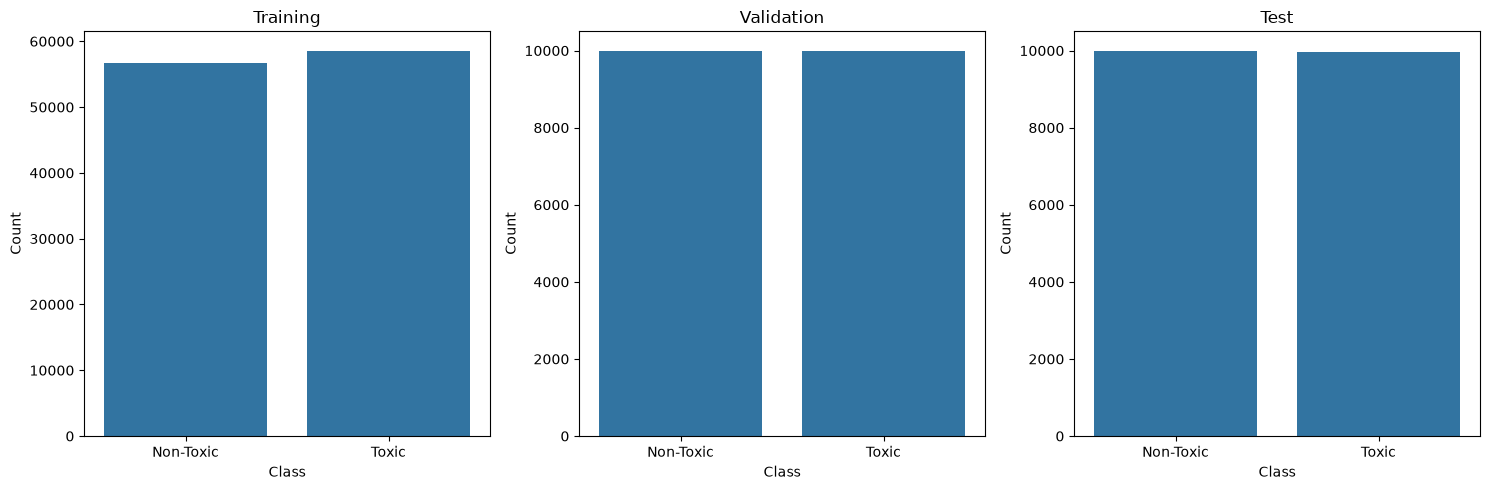

In [18]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

datasets_for_plot = [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]

for ax, (name, df) in zip(
    axes,
    datasets_for_plot
):

    sns.countplot(
        x="toxic",
        data=df,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Class")
    ax.set_ylabel("Count")

    ax.set_xticks([0, 1])

    ax.set_xticklabels([
        "Non-Toxic",
        "Toxic"
    ])

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "class_distribution.png"
    ),
    dpi=300
)

plt.show()

In [19]:
print("=" * 70)
print("BASELINE MODEL")
print("=" * 70)

baseline_vectorizer = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_baseline = baseline_vectorizer.fit_transform(
    train_df["comment_text"]
)

X_val_baseline = baseline_vectorizer.transform(
    val_df["comment_text"]
)

X_test_baseline = baseline_vectorizer.transform(
    test_df["comment_text"]
)

baseline_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=SEED
)

baseline_model.fit(
    X_train_baseline,
    train_df["toxic"]
)

print("Baseline model trained.")

BASELINE MODEL
Baseline model trained.


In [20]:
baseline_test_probabilities = baseline_model.predict_proba(
    X_test_baseline
)[:, 1]

baseline_test_predictions = (
    baseline_test_probabilities >= 0.50
).astype(int)

baseline_accuracy = accuracy_score(
    test_df["toxic"],
    baseline_test_predictions
)

baseline_precision = precision_score(
    test_df["toxic"],
    baseline_test_predictions,
    zero_division=0
)

baseline_recall = recall_score(
    test_df["toxic"],
    baseline_test_predictions,
    zero_division=0
)

baseline_f1 = f1_score(
    test_df["toxic"],
    baseline_test_predictions,
    zero_division=0
)

baseline_roc_auc = roc_auc_score(
    test_df["toxic"],
    baseline_test_probabilities
)

baseline_pr_auc = average_precision_score(
    test_df["toxic"],
    baseline_test_probabilities
)

print("=" * 70)
print("BASELINE RESULTS")
print("=" * 70)

print(f"Accuracy  : {baseline_accuracy:.4f}")
print(f"Precision : {baseline_precision:.4f}")
print(f"Recall    : {baseline_recall:.4f}")
print(f"F1        : {baseline_f1:.4f}")
print(f"ROC-AUC   : {baseline_roc_auc:.4f}")
print(f"PR-AUC    : {baseline_pr_auc:.4f}")

BASELINE RESULTS
Accuracy  : 0.9298
Precision : 0.9335
Recall    : 0.9252
F1        : 0.9293
ROC-AUC   : 0.9790
PR-AUC    : 0.9784


In [21]:
MODEL_NAME = "distilbert-base-uncased"

MAX_LENGTH = 256

id2label = {
    0: "NON_TOXIC",
    1: "TOXIC"
}

label2id = {
    "NON_TOXIC": 0,
    "TOXIC": 1
}

print("Model:", MODEL_NAME)
print("Maximum sequence length:", MAX_LENGTH)

Model: distilbert-base-uncased
Maximum sequence length: 256


In [23]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print("Tokenizer loaded successfully.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded successfully.


In [24]:
sample_text = train_df[
    "comment_text"
].iloc[0]

print("Original text:")
print(sample_text)

print("\nTokens:")
print(tokenizer.tokenize(sample_text))

print("\nToken IDs:")
print(
    tokenizer(
        sample_text
    )["input_ids"]
)

Original text:
Wasn't me, asshole.  Check your fucking IP's before you go shooting off your mouth.

Tokens:
['wasn', "'", 't', 'me', ',', 'asshole', '.', 'check', 'your', 'fucking', 'ip', "'", 's', 'before', 'you', 'go', 'shooting', 'off', 'your', 'mouth', '.']

Token IDs:
[101, 2347, 1005, 1056, 2033, 1010, 22052, 1012, 4638, 2115, 8239, 12997, 1005, 1055, 2077, 2017, 2175, 5008, 2125, 2115, 2677, 1012, 102]


In [25]:
train_df_hf = train_df.rename(
    columns={
        "toxic": "labels"
    }
)

val_df_hf = val_df.rename(
    columns={
        "toxic": "labels"
    }
)

test_df_hf = test_df.rename(
    columns={
        "toxic": "labels"
    }
)

train_dataset = Dataset.from_pandas(
    train_df_hf,
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df_hf,
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_df_hf,
    preserve_index=False
)

print(train_dataset)
print(val_dataset)
print(test_dataset)

Dataset({
    features: ['comment_text', 'labels'],
    num_rows: 115354
})
Dataset({
    features: ['comment_text', 'labels'],
    num_rows: 19980
})
Dataset({
    features: ['comment_text', 'labels'],
    num_rows: 19973
})


In [26]:
def tokenize_function(examples):

    return tokenizer(
        examples["comment_text"],
        truncation=True,
        max_length=MAX_LENGTH
    )


tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True,
    desc="Tokenizing training"
)

tokenized_val = val_dataset.map(
    tokenize_function,
    batched=True,
    desc="Tokenizing validation"
)

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True,
    desc="Tokenizing test"
)

print("Tokenization completed.")

Tokenizing training:   0%|          | 0/115354 [00:00<?, ? examples/s]

Tokenizing validation:   0%|          | 0/19980 [00:00<?, ? examples/s]

Tokenizing test:   0%|          | 0/19973 [00:00<?, ? examples/s]

Tokenization completed.


In [27]:
tokenized_train = tokenized_train.remove_columns(
    ["comment_text"]
)

tokenized_val = tokenized_val.remove_columns(
    ["comment_text"]
)

tokenized_test = tokenized_test.remove_columns(
    ["comment_text"]
)

print(tokenized_train.column_names)

['labels', 'input_ids', 'token_type_ids', 'attention_mask']


In [28]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

print("Pretrained DistilBERT loaded.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Pretrained DistilBERT loaded.


In [29]:
print("DISTILBERT MODEL ARCHITECTURE")
print(model)

DISTILBERT MODEL ARCHITECTURE
DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
 

In [30]:
config = model.config

print("Model type          :", config.model_type)
print("Hidden size         :", config.dim)
print("Number of layers    :", config.n_layers)
print("Attention heads     :", config.n_heads)
print("Intermediate size   :", config.hidden_dim)
print("Vocabulary size     :", config.vocab_size)
print("Maximum positions   :", config.max_position_embeddings)
print("Number of labels    :", config.num_labels)
print("Labels              :", config.id2label)

Model type          : distilbert
Hidden size         : 768
Number of layers    : 6
Attention heads     : 12
Intermediate size   : 3072
Vocabulary size     : 30522
Maximum positions   : 512
Number of labels    : 2
Labels              : {0: 'NON_TOXIC', 1: 'TOXIC'}


In [31]:
total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

non_trainable_parameters = (
    total_parameters -
    trainable_parameters
)

print("MODEL PARAMETER SUMMARY")

print(
    f"Total parameters     : {total_parameters:,}"
)

print(
    f"Trainable parameters : {trainable_parameters:,}"
)

print(
    f"Non-trainable        : {non_trainable_parameters:,}"
)

MODEL PARAMETER SUMMARY
Total parameters     : 66,955,010
Trainable parameters : 66,955,010
Non-trainable        : 0


In [32]:

print("CLASSIFICATION HEAD")

print(model.classifier)

CLASSIFICATION HEAD
Linear(in_features=768, out_features=2, bias=True)


In [33]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("Data collator created.")

Data collator created.


In [34]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(
        logits,
        axis=-1
    )

    probabilities = torch.softmax(
        torch.tensor(logits),
        dim=1
    ).numpy()[:, 1]

    return {
        "accuracy": accuracy_score(
            labels,
            predictions
        ),

        "precision": precision_score(
            labels,
            predictions,
            zero_division=0
        ),

        "recall": recall_score(
            labels,
            predictions,
            zero_division=0
        ),

        "f1": f1_score(
            labels,
            predictions,
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            labels,
            probabilities
        ),

        "pr_auc": average_precision_score(
            labels,
            probabilities
        )
    }

In [35]:
OUTPUT_DIR = os.path.join(
    RESULTS_DIR,
    "training_output"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

USE_FP16 = torch.cuda.is_available()

training_args = TrainingArguments(

    output_dir=OUTPUT_DIR,

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=32,

    num_train_epochs=3,

    weight_decay=0.01,

    load_best_model_at_end=True,

    metric_for_best_model="f1",

    greater_is_better=True,

    logging_strategy="steps",

    logging_steps=100,

    save_total_limit=2,

    report_to="none",

    fp16=USE_FP16,

    bf16=False,

    seed=SEED,

    data_seed=SEED
)

print("Training configuration created.")

Training configuration created.


In [36]:
trainer = Trainer(

    model=model,

    args=training_args,

    train_dataset=tokenized_train,

    eval_dataset=tokenized_val,

    processing_class=tokenizer,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

print("Trainer created successfully.")

Trainer created successfully.


In [37]:
print("STARTING DISTILBERT FINE-TUNING")

print("Model:", MODEL_NAME)
print("Task: Toxic / Non-Toxic classification")
print("Device:", DEVICE)
print("Epochs:", 3)
print("Learning rate:", 2e-5)

print("\nFine-tuning starts now...")

STARTING DISTILBERT FINE-TUNING
Model: distilbert-base-uncased
Task: Toxic / Non-Toxic classification
Device: mps
Epochs: 3
Learning rate: 2e-05

Fine-tuning starts now...


In [38]:
train_result = trainer.train()

/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc,Pr Auc
1,0.121618,0.137111,0.953604,0.934363,0.975651,0.954561,0.991739,0.991438
2,0.077544,0.158279,0.956557,0.950643,0.963026,0.956794,0.992083,0.991791
3,0.037934,0.195670,0.956456,0.949034,0.964629,0.956768,0.991687,0.991426


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [39]:
print("FINE-TUNING COMPLETED")

print("\nTraining metrics:")

print(train_result.metrics)

FINE-TUNING COMPLETED

Training metrics:
{'train_runtime': 64078.0659, 'train_samples_per_second': 5.401, 'train_steps_per_second': 0.338, 'total_flos': 1.955334971861772e+16, 'train_loss': 0.0976643328968706, 'epoch': 3.0}


In [40]:
history_df = pd.DataFrame(
    trainer.state.log_history
)

display(history_df)

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_precision,eval_recall,eval_f1,eval_roc_auc,eval_pr_auc,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.355548,7.635471,1.990846e-05,0.013870,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.237031,5.128471,1.981600e-05,0.027739,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.195203,10.559303,1.972353e-05,0.041609,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.168701,4.242933,1.963107e-05,0.055479,400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.178998,5.805269,1.953860e-05,0.069348,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
215,0.074430,0.284781,2.135922e-07,2.968100,21400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
216,0.045624,43.617371,1.211281e-07,2.981969,21500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
217,0.037934,5.583837,2.866389e-08,2.995839,21600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
218,NaN,NaN,NaN,3.000000,21630,0.19567,0.956456,0.949034,0.964629,0.956768,0.991687,0.991426,301.3884,66.293,2.074,NaN,NaN,NaN,NaN,NaN


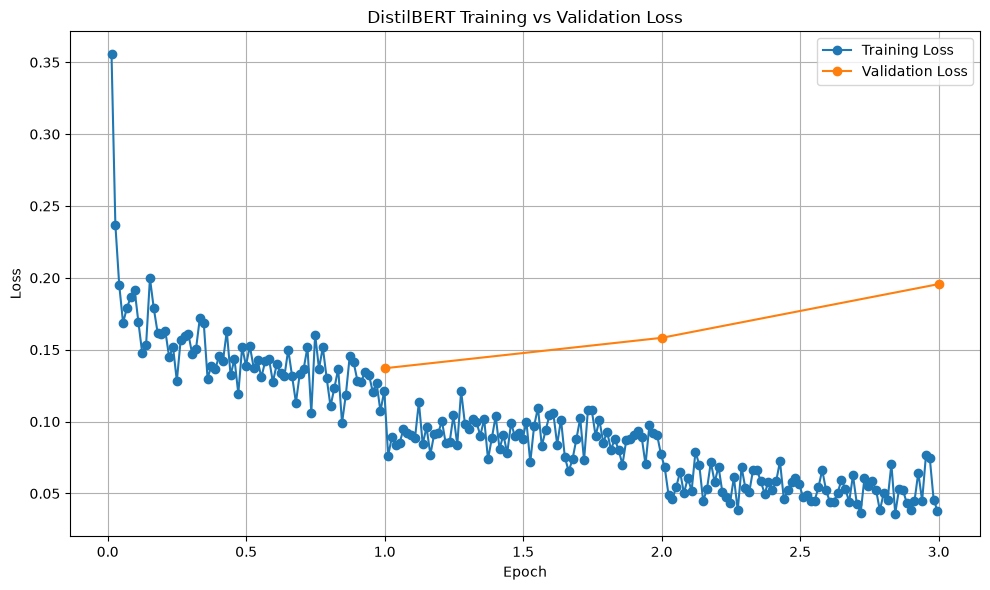

In [41]:
train_history = history_df[
    history_df["loss"].notna()
]

eval_history = history_df[
    history_df["eval_loss"].notna()
]

plt.figure(
    figsize=(10, 6)
)

if not train_history.empty:

    plt.plot(
        train_history["epoch"],
        train_history["loss"],
        marker="o",
        label="Training Loss"
    )

if not eval_history.empty:

    plt.plot(
        eval_history["epoch"],
        eval_history["eval_loss"],
        marker="o",
        label="Validation Loss"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "DistilBERT Training vs Validation Loss"
)

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "training_validation_loss.png"
    ),
    dpi=300
)

plt.show()

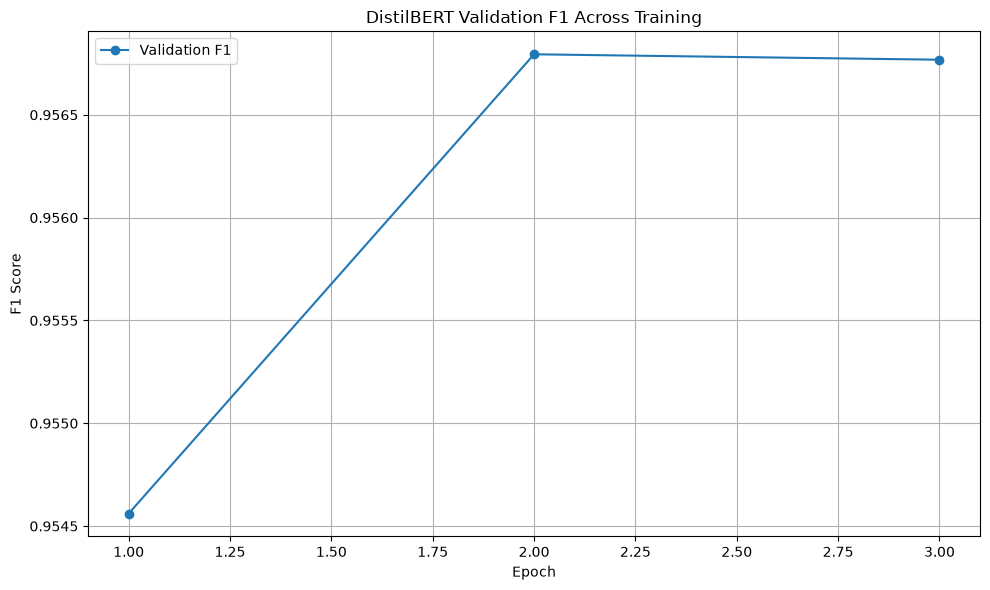

In [42]:
eval_f1_history = history_df[
    history_df["eval_f1"].notna()
]

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    eval_f1_history["epoch"],
    eval_f1_history["eval_f1"],
    marker="o",
    label="Validation F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")

plt.title(
    "DistilBERT Validation F1 Across Training"
)

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "validation_f1.png"
    ),
    dpi=300
)

plt.show()

In [43]:
validation_results = trainer.evaluate(
    eval_dataset=tokenized_val
)

print("=" * 70)
print("VALIDATION RESULTS")
print("=" * 70)

for key, value in validation_results.items():

    if isinstance(value, float):

        print(
            f"{key}: {value:.4f}"
        )

    else:

        print(
            f"{key}: {value}"
        )

/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Roc Auc,Pr Auc
0.037934,0.158279,3,0.956557,0.950643,0.963026,0.956794,0.992083,0.991791


VALIDATION RESULTS
eval_loss: 0.1583
eval_accuracy: 0.9566
eval_precision: 0.9506
eval_recall: 0.9630
eval_f1: 0.9568
eval_roc_auc: 0.9921
eval_pr_auc: 0.9918


In [44]:
val_output = trainer.predict(
    tokenized_val
)

val_logits = val_output.predictions

val_probabilities = torch.softmax(
    torch.tensor(val_logits),
    dim=1
).numpy()[:, 1]

val_labels = val_df[
    "toxic"
].values

print("Validation predictions generated.")

/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Validation predictions generated.


In [45]:
thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

threshold_results = []

for threshold in thresholds:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({

        "threshold": threshold,

        "accuracy": accuracy_score(
            val_labels,
            predictions
        ),

        "precision": precision_score(
            val_labels,
            predictions,
            zero_division=0
        ),

        "recall": recall_score(
            val_labels,
            predictions,
            zero_division=0
        ),

        "f1": f1_score(
            val_labels,
            predictions,
            zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(
    threshold_results
)

display(threshold_results_df)

,threshold,accuracy,precision,recall,f1
0,0.10,0.955405,0.939549,0.973347,0.956149
1,0.15,0.955956,0.942263,0.971343,0.956582
2,0.20,0.956256,0.944195,0.969739,0.956797
3,0.25,0.956156,0.945053,0.968537,0.956651
4,0.30,0.956406,0.946476,0.967435,0.956841
5,0.35,0.956206,0.947244,0.966132,0.956595
6,0.40,0.956406,0.948587,0.965030,0.956738
7,0.45,0.956507,0.949837,0.963828,0.956781
8,0.50,0.956557,0.950643,0.963026,0.956794
9,0.55,0.956557,0.951447,0.962124,0.956756


In [46]:
best_row = threshold_results_df.loc[
    threshold_results_df["f1"].idxmax()
]

best_threshold = float(
    best_row["threshold"]
)

best_validation_f1 = float(
    best_row["f1"]
)

print("=" * 70)
print("BEST THRESHOLD")
print("=" * 70)

print(
    f"Threshold : {best_threshold:.2f}"
)

print(
    f"Validation F1 : {best_validation_f1:.4f}"
)

BEST THRESHOLD
Threshold : 0.30
Validation F1 : 0.9568


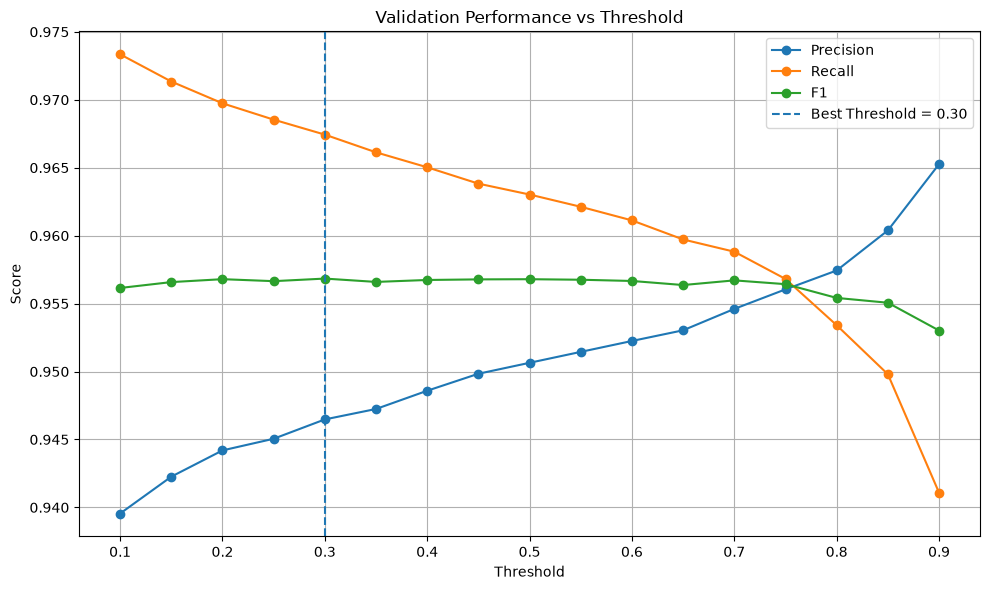

In [47]:
plt.figure(
    figsize=(10, 6)
)

plt.plot(
    threshold_results_df["threshold"],
    threshold_results_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results_df["threshold"],
    threshold_results_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results_df["threshold"],
    threshold_results_df["f1"],
    marker="o",
    label="F1"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best Threshold = {best_threshold:.2f}"
)

plt.xlabel("Threshold")
plt.ylabel("Score")

plt.title(
    "Validation Performance vs Threshold"
)

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "threshold_performance.png"
    ),
    dpi=300
)

plt.show()

In [48]:

print("FINAL TEST EVALUATION")

test_output = trainer.predict(
    tokenized_test
)

test_logits = test_output.predictions

test_probabilities = torch.softmax(
    torch.tensor(test_logits),
    dim=1
).numpy()[:, 1]

test_labels = test_df[
    "toxic"
].values

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("Test predictions generated.")

FINAL TEST EVALUATION


/Users/ajay/jupyter/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Test predictions generated.


In [49]:
test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

test_precision = precision_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_recall = recall_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    test_labels,
    test_probabilities
)

test_pr_auc = average_precision_score(
    test_labels,
    test_probabilities
)

print("=" * 70)
print("FINAL DISTILBERT RESULTS")
print("=" * 70)

print(f"Threshold : {best_threshold:.2f}")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1        : {test_f1:.4f}")
print(f"ROC-AUC   : {test_roc_auc:.4f}")
print(f"PR-AUC    : {test_pr_auc:.4f}")

FINAL DISTILBERT RESULTS
Threshold : 0.30
Accuracy  : 0.9569
Precision : 0.9480
Recall    : 0.9668
F1        : 0.9573
ROC-AUC   : 0.9929
PR-AUC    : 0.9928


In [50]:
report = classification_report(
    test_labels,
    test_predictions,
    target_names=[
        "Non-Toxic",
        "Toxic"
    ],
    zero_division=0
)

print(report)

with open(
    os.path.join(
        RESULTS_DIR,
        "classification_report.txt"
    ),
    "w"
) as file:

    file.write(report)

              precision    recall  f1-score   support

   Non-Toxic       0.97      0.95      0.96     10000
       Toxic       0.95      0.97      0.96      9973

    accuracy                           0.96     19973
   macro avg       0.96      0.96      0.96     19973
weighted avg       0.96      0.96      0.96     19973



[[9471  529]
 [ 331 9642]]


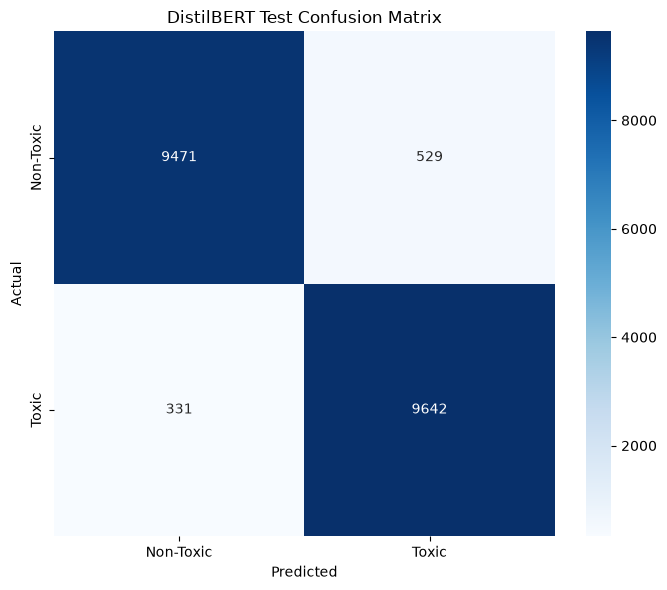

In [51]:
cm = confusion_matrix(
    test_labels,
    test_predictions
)

print(cm)

plt.figure(
    figsize=(7, 6)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Non-Toxic",
        "Toxic"
    ],
    yticklabels=[
        "Non-Toxic",
        "Toxic"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "DistilBERT Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "confusion_matrix.png"
    ),
    dpi=300
)

plt.show()

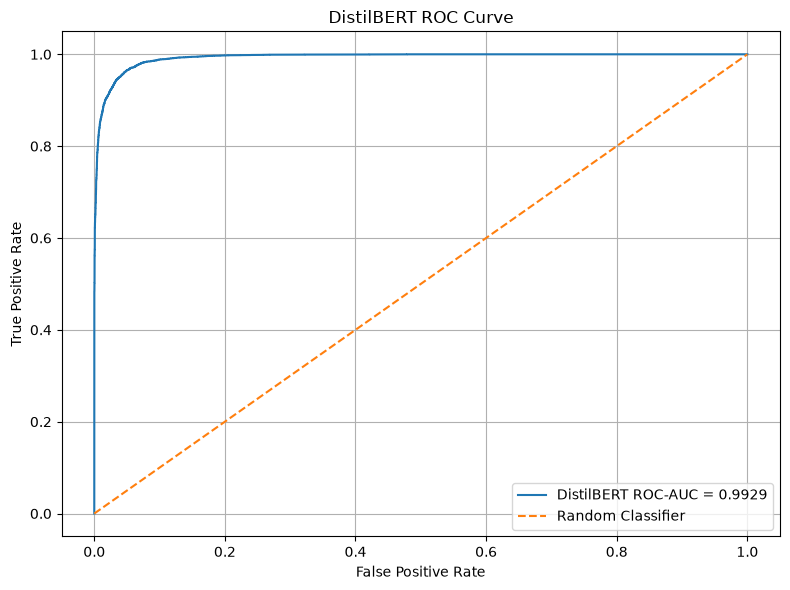

In [52]:
fpr, tpr, _ = roc_curve(
    test_labels,
    test_probabilities
)

plt.figure(
    figsize=(8, 6)
)

plt.plot(
    fpr,
    tpr,
    label=f"DistilBERT ROC-AUC = {test_roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "DistilBERT ROC Curve"
)

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "roc_curve.png"
    ),
    dpi=300
)

plt.show()

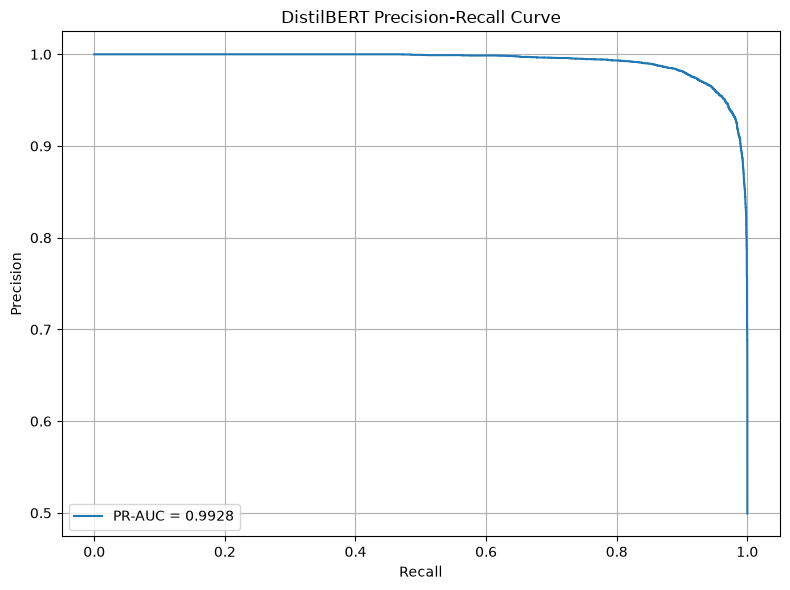

In [53]:
precision_curve, recall_curve, _ = precision_recall_curve(
    test_labels,
    test_probabilities
)

plt.figure(
    figsize=(8, 6)
)

plt.plot(
    recall_curve,
    precision_curve,
    label=f"PR-AUC = {test_pr_auc:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "DistilBERT Precision-Recall Curve"
)

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "precision_recall_curve.png"
    ),
    dpi=300
)

plt.show()

In [54]:
comparison_df = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Baseline": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1,
        baseline_roc_auc,
        baseline_pr_auc
    ],

    "Fine-Tuned DistilBERT": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_roc_auc,
        test_pr_auc
    ]
})

display(comparison_df)

,Metric,Baseline,Fine-Tuned DistilBERT
0,Accuracy,0.929755,0.956942
1,Precision,0.933529,0.947989
2,Recall,0.925198,0.966810
3,F1,0.929345,0.957307
4,ROC-AUC,0.979032,0.992860
5,PR-AUC,0.978388,0.992772


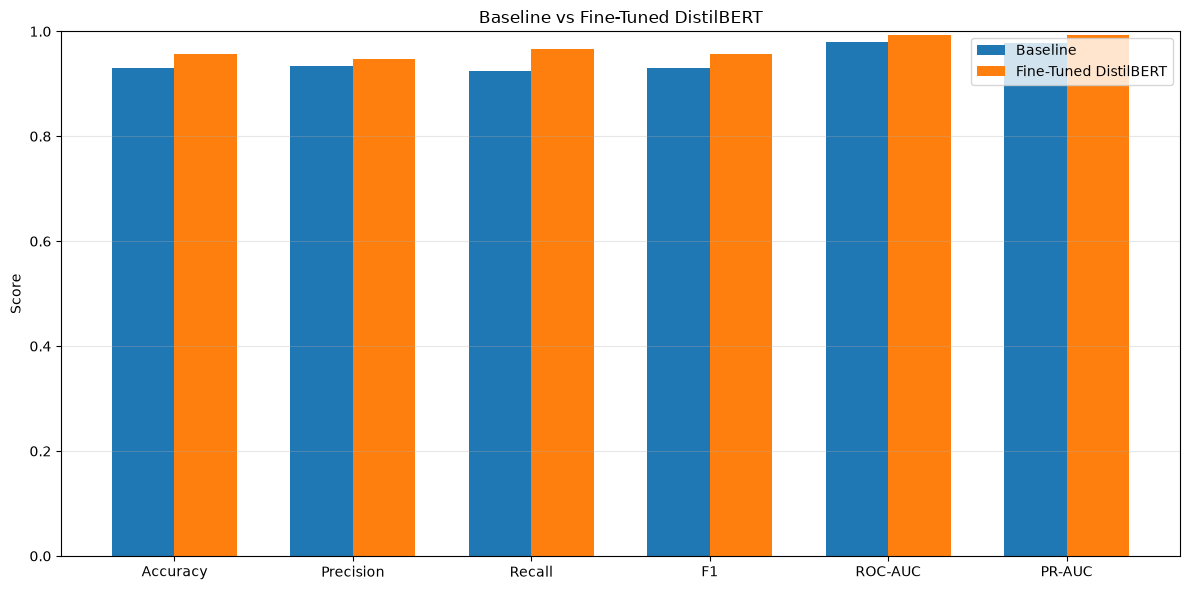

In [55]:
x = np.arange(
    len(comparison_df["Metric"])
)

width = 0.35

plt.figure(
    figsize=(12, 6)
)

plt.bar(
    x - width / 2,
    comparison_df["Baseline"],
    width,
    label="Baseline"
)

plt.bar(
    x + width / 2,
    comparison_df["Fine-Tuned DistilBERT"],
    width,
    label="Fine-Tuned DistilBERT"
)

plt.xticks(
    x,
    comparison_df["Metric"]
)

plt.ylabel("Score")
plt.ylim(0, 1)

plt.title(
    "Baseline vs Fine-Tuned DistilBERT"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "baseline_vs_finetuned.png"
    ),
    dpi=300
)

plt.show()

In [56]:
comparison_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "baseline_vs_finetuned.csv"
    ),
    index=False
)

print("Comparison saved.")

Comparison saved.


In [57]:
final_results = {

    "model": MODEL_NAME,

    "device": str(DEVICE),

    "python_version": sys.version.split()[0],

    "pytorch_version": torch.__version__,

    "transformers_version": transformers.__version__,

    "max_length": MAX_LENGTH,

    "epochs": 3,

    "learning_rate": 2e-5,

    "best_threshold": best_threshold,

    "baseline": {

        "accuracy": baseline_accuracy,
        "precision": baseline_precision,
        "recall": baseline_recall,
        "f1": baseline_f1,
        "roc_auc": baseline_roc_auc,
        "pr_auc": baseline_pr_auc
    },

    "fine_tuned": {

        "accuracy": test_accuracy,
        "precision": test_precision,
        "recall": test_recall,
        "f1": test_f1,
        "roc_auc": test_roc_auc,
        "pr_auc": test_pr_auc
    }
}

with open(
    os.path.join(
        RESULTS_DIR,
        "final_metrics.json"
    ),
    "w"
) as file:

    json.dump(
        final_results,
        file,
        indent=4,
        default=float
    )

print("Final metrics saved.")

Final metrics saved.


In [58]:

print("SAVING FINE-TUNED MODEL")

trainer.save_model(
    MODEL_DIR
)

tokenizer.save_pretrained(
    MODEL_DIR
)

print("Model saved to:")
print(MODEL_DIR)

SAVING FINE-TUNED MODEL


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to:
/Users/ajay/baseline_models/models/distilbert-toxic-final


In [59]:
threshold_path = os.path.join(
    MODEL_DIR,
    "threshold.json"
)

with open(
    threshold_path,
    "w"
) as file:

    json.dump(
        {
            "threshold": best_threshold
        },
        file,
        indent=4
    )

print(
    "Threshold saved:",
    best_threshold
)

Threshold saved: 0.30000000000000004


In [60]:
loaded_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_DIR
)

loaded_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_DIR
)

loaded_model.eval()

loaded_model.to(
    DEVICE
)

print("Saved model loaded successfully.")
print("Inference device:", DEVICE)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Saved model loaded successfully.
Inference device: mps


In [61]:
with open(
    threshold_path,
    "r"
) as file:

    threshold_config = json.load(file)

loaded_threshold = threshold_config[
    "threshold"
]


def detect_toxicity(
    message,
    threshold=loaded_threshold
):

    inputs = loaded_tokenizer(
        message,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )

    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = loaded_model(
            **inputs
        )

    probabilities = torch.softmax(
        outputs.logits,
        dim=1
    )[0]

    non_toxic_probability = float(
        probabilities[0].cpu()
    )

    toxic_probability = float(
        probabilities[1].cpu()
    )

    if toxic_probability >= threshold:

        category = "Toxic"

    else:

        category = "Non-Toxic"

    return {

        "message": message,

        "category": category,

        "toxic_probability": round(
            toxic_probability,
            4
        ),

        "non_toxic_probability": round(
            non_toxic_probability,
            4
        ),

        "threshold": threshold
    }

In [62]:
example_messages = [

    "Hello, how are you?",

    "Thank you for your help.",

    "You are an idiot.",

    "I really appreciate your work.",

    "You are completely useless.",

    "Have a wonderful day."
]


for message in example_messages:

    result = detect_toxicity(
        message
    )

    print("\nMessage:", result["message"])

    print(
        "Category:",
        result["category"]
    )

    print(
        "Toxic probability:",
        result["toxic_probability"]
    )

    print(
        "Non-toxic probability:",
        result["non_toxic_probability"]
    )


Message: Hello, how are you?
Category: Non-Toxic
Toxic probability: 0.0004
Non-toxic probability: 0.9996

Message: Thank you for your help.
Category: Non-Toxic
Toxic probability: 0.0002
Non-toxic probability: 0.9998

Message: You are an idiot.
Category: Toxic
Toxic probability: 0.9996
Non-toxic probability: 0.0004

Message: I really appreciate your work.
Category: Non-Toxic
Toxic probability: 0.0004
Non-toxic probability: 0.9996

Message: You are completely useless.
Category: Toxic
Toxic probability: 0.9991
Non-toxic probability: 0.0009

Message: Have a wonderful day.
Category: Non-Toxic
Toxic probability: 0.0013
Non-toxic probability: 0.9987


In [63]:
message = "You are completely useless."

result = detect_toxicity(
    message
)

result

{'message': 'You are completely useless.',
 'category': 'Toxic',
 'toxic_probability': 0.9991,
 'non_toxic_probability': 0.0009,
 'threshold': 0.30000000000000004}

In [64]:
print("FINAL PROJECT SUMMARY")

print("\nModel:", MODEL_NAME)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

print("\nBest threshold:", best_threshold)

print("\nFINAL TEST PERFORMANCE")
print("-" * 70)

print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1        : {test_f1:.4f}")
print(f"ROC-AUC   : {test_roc_auc:.4f}")
print(f"PR-AUC    : {test_pr_auc:.4f}")

print("\nModel directory:")
print(MODEL_DIR)

print("\nResults directory:")
print(RESULTS_DIR)

print("\nCompleted successfully.")

FINAL PROJECT SUMMARY

Model: distilbert-base-uncased
Training samples: 115354
Validation samples: 19980
Test samples: 19973

Best threshold: 0.30000000000000004

FINAL TEST PERFORMANCE
----------------------------------------------------------------------
Accuracy  : 0.9569
Precision : 0.9480
Recall    : 0.9668
F1        : 0.9573
ROC-AUC   : 0.9929
PR-AUC    : 0.9928

Model directory:
/Users/ajay/baseline_models/models/distilbert-toxic-final

Results directory:
/Users/ajay/baseline_models/results

Completed successfully.
